# Employee Attrition Prediction Using Machine Learning

#### 1. Problem Statement and Project Overview

Employee attrition is a challenge for many organizations because losing employees can increase recruitment and training costs and affect productivity.

In this project, I used the IBM HR Analytics Employee Attrition dataset to build a machine learning model that predicts whether an employee is likely to leave a company based on factors such as age, monthly income, job satisfaction, overtime, and years of experience.

The aim is to explore the factors associated with employee attrition, compare different machine learning algorithms, and identify a model that can help organizations better understand employee retention patterns.

I approached this as a binary classification problem, where `0` represents employees who stayed and `1` represents employees who left.

#### 2. Project Objectives

The main objectives of this project are to:

1. Explore and clean the dataset, identify missing values, and analyze the distribution of employee attrition.
2. Perform Exploratory Data Analysis (EDA) and feature importance analysis to understand the factors associated with attrition.
3. Prepare the data for machine learning through encoding, scaling, and splitting it into training, validation, and test datasets.
4. Train and tune Logistic Regression, Random Forest, and XGBoost models.
5. Compare model performance using accuracy, precision, recall, F1-score, and ROC-AUC, and select the most suitable model.
6. Save the final model and deploy it as a Flask web service using Docker.

#### 3. Dataset Description

I used the IBM HR Analytics Employee Attrition & Performance dataset, which contains 1,470 employee records and 35 columns.

The dataset includes information such as employee age, department, monthly income, job role, overtime, job satisfaction, and years at the company.

The target variable is `Attrition`, which indicates whether an employee left the company (`Yes`) or stayed (`No`).

Out of the 1,470 employees, 237 left the company, while 1,233 stayed. This means approximately 16.1% of employees left, making the dataset imbalanced.

Because of this imbalance, I focused on metrics such as precision, recall, F1-score, and ROC-AUC rather than relying on accuracy alone.

The dataset is synthetic and is used here to demonstrate the machine learning process rather than to make actual employment decisions.

## Importing libraries

I began by importing the libraries needed to load and explore the data. Pandas helps me work with tables, NumPy supports numerical operations, and Scikit-learn provides the machine learning tools used later in the notebook

In [70]:
import pandas as pd
import os
import numpy as np
from sklearn.linear_model import LogisticRegression

## Data Preparation

I loaded the employee dataset from a CSV file and displayed the first five rows. This gave me an initial look at the columns and the kinds of information recorded for each employee. The CSV file must be available in the same working folder for this cell to run.

In [71]:
df = pd.read_csv('New_HR-Employee-Attrition.csv')
df.head(5)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.head().T

,0,1,2,3,4
Age,41,49,37,33,27
Attrition,Yes,No,Yes,No,No
BusinessTravel,Travel_Rarely,Travel_Frequently,Travel_Rarely,Travel_Frequently,Travel_Rarely
DailyRate,1102,279,1373,1392,591
Department,Sales,Research & Development,Research & Development,Research & Development,Research & Development
DistanceFromHome,1,8,2,3,2
Education,2,1,2,4,1
EducationField,Life Sciences,Life Sciences,Other,Life Sciences,Medical
EmployeeCount,1,1,1,1,1
EmployeeNumber,1,2,4,5,7


I transposed the first few records so that the feature names appear vertically. With many columns in the dataset, this view makes it easier to inspect individual variables.

In [4]:
df.dtypes

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesL

I checked the data types to see which columns contain numbers and which contain text. This matters because most machine learning algorithms cannot use raw text categories without encoding them first.

In [5]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

I checked for missing values in each column. In this dataset, the missing-value check did not show missing entries, but I still included imputers in the preprocessing pipeline to make the training process more robust.

In [6]:
df.Attrition                   

0       Yes
1        No
2       Yes
3        No
4        No
       ... 
1465     No
1466     No
1467     No
1468     No
1469     No
Name: Attrition, Length: 1470, dtype: str

I inspected the target column, Attrition, before changing its values. At this stage it uses the labels Yes and No.

In [7]:
# Convert the target column to binary integers
df.Attrition = (df.Attrition == 'Yes').astype(int)

# Print the first few rows of the converted column
print(df.Attrition.head())

0    1
1    0
2    1
3    0
4    0
Name: Attrition, dtype: int64


I converted Attrition into a binary target: Yes becomes 1 and No becomes 0. This makes the target suitable for binary classification and allows me to calculate the proportion of employees who left using the mean.

## Setting up the validation framework

In [9]:

from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1,
    stratify=df['Attrition']
)

len(df_full_train), len(df_test)


(1176, 294)

I first separated 20% of the records as a test dataset and kept the remaining 80% for training and validation. I used stratify so the proportion of employees who left would be similar across the split. The test set is kept aside until the final model is chosen.

#### Split training into training and validation datasets

In [109]:

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1,
    stratify=df_full_train['Attrition']
)

len(df_train), len(df_val), len(df_test)


(882, 294, 294)

I split the remaining data again, using 25% of it for validation. This gives an overall split of 60% training, 20% validation and 20% testing: 882, 294 and 294 employees respectively. I used the training data to fit models and the validation data to compare them.

In [110]:

print("Training:")
print(df_train.Attrition.value_counts(normalize=True))

print("\nValidation:")
print(df_val.Attrition.value_counts(normalize=True))

print("\nTesting:")
print(df_test.Attrition.value_counts(normalize=True))


Training:
Attrition
0    0.839002
1    0.160998
Name: proportion, dtype: float64

Validation:
Attrition
0    0.836735
1    0.163265
Name: proportion, dtype: float64

Testing:
Attrition
0    0.840136
1    0.159864
Name: proportion, dtype: float64


I checked the target distribution in the training and validation sets. This is a useful way to confirm that stratified splitting kept the class proportions similar.

In [111]:

global_Attrition_rate = df_full_train['Attrition'].mean()

print("Global Attrition Rate:", global_Attrition_rate)




Global Attrition Rate: 0.16156462585034015


I calculated the overall attrition rate in the combined training-and-validation data. Since Attrition is coded as 0 and 1, its mean is the share of employees who left. The dataset is imbalanced: most employees stayed.

In [112]:

# Reset indices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

# Extract targets
y_train = df_train['Attrition'].copy()
y_val = df_val['Attrition'].copy()
y_test = df_test['Attrition'].copy()

# Extract features
X_train = df_train.drop(columns=['Attrition'])
X_val = df_val.drop(columns=['Attrition'])
X_test = df_test.drop(columns=['Attrition'])

print(X_train.shape, X_val.shape, X_test.shape)


(882, 34) (294, 34) (294, 34)


I reset the row indices and separated the target (y) from the predictor columns (X). Keeping the target out of X is essential; otherwise, the model would be given the answer it is supposed to predict.

In [113]:
constant_columns = df.columns[df.nunique() <= 1]

print(constant_columns.tolist())

['EmployeeCount', 'Over18', 'StandardHours']


Before removing any columns, I checked for features with only one unique value. A constant feature cannot distinguish between employees who stayed and employees who left.

In [114]:

# Columns to remove
columns_to_drop = [
    'EmployeeNumber',
    'EmployeeCount',
    'Over18',
    'StandardHours'
]

# Remove unnecessary columns from feature datasets
X_train = X_train.drop(columns=columns_to_drop)
X_val = X_val.drop(columns=columns_to_drop)
X_test = X_test.drop(columns=columns_to_drop)

# Check dimensions
print(X_train.shape, X_val.shape, X_test.shape)


(882, 30) (294, 30) (294, 30)


I removed EmployeeNumber, EmployeeCount, Over18 and StandardHours from the predictor datasets. EmployeeNumber is an identifier, while the other three columns are constant in this dataset. I applied the same removals to training, validation and test data so their columns remain consistent. This left 30 predictor features.

#### Notes on removing features
I considered whether each column contained useful information before dropping it. Identifiers and columns with the same value for every employee do not help distinguish the two target classes. I did not remove columns solely because their mutual information score was low.

#### Calculate mutual information for numerical features

In [115]:

# Identify numerical features
numerical = X_train.select_dtypes(
    include=['number']
).columns.tolist()

# Identify categorical features
categorical = X_train.select_dtypes(
    include=['str', 'object', 'category']
).columns.tolist()

print("Numerical features:", len(numerical))
print("Categorical features:", len(categorical))
print("Total features:", len(numerical) + len(categorical))

print("\nNumerical columns:")
print(numerical)

print("\nCategorical columns:")
print(categorical)


Numerical features: 23
Categorical features: 7
Total features: 30

Numerical columns:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical columns:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


I used mutual information to explore how much information each feature provides about the attrition target. Higher scores suggest a stronger statistical relationship, but they do not prove that a feature causes employees to leave. I calculated scores using the training data to avoid learning from the test set.

In [116]:
from sklearn.feature_selection import mutual_info_classif

# Select numerical features
X_train_numeric = X_train.select_dtypes(
    include=['int64', 'float64']
).copy()

# Calculate mutual information
mi_scores = mutual_info_classif(
    X_train_numeric,
    y_train,
    random_state=42
)

# Create a dataframe
mi_df = pd.DataFrame({
    'Feature': X_train_numeric.columns,
    'MI_Score': mi_scores
})

# Sort by importance
mi_df = mi_df.sort_values(
    by='MI_Score',
    ascending=False
)

mi_df


,Feature,MI_Score
9,MonthlyIncome,0.041551
19,YearsAtCompany,0.030715
20,YearsInCurrentRole,0.029619
22,YearsWithCurrManager,0.022365
0,Age,0.020864
11,NumCompaniesWorked,0.018704
15,StockOptionLevel,0.018505
12,PercentSalaryHike,0.016945
7,JobLevel,0.013865
14,RelationshipSatisfaction,0.011538


For numerical features, I used mutual_info_classif and sorted the results from highest to lowest. This helped me identify promising variables to investigate further, such as monthly income and employee tenure. A low score by itself is not enough reason to remove a feature.

In [117]:

from sklearn.metrics import mutual_info_score

categorical = [
    'BusinessTravel',
    'Department',
    'EducationField',
    'Gender',
    'JobRole',
    'MaritalStatus',
    'OverTime'
]

categorical_mi = []

for col in categorical:
    score = mutual_info_score(
        df_train[col],
        y_train
    )

    categorical_mi.append({
        'Feature': col,
        'MI_Score': score
    })

categorical_mi_df = pd.DataFrame(categorical_mi)

categorical_mi_df = categorical_mi_df.sort_values(
    'MI_Score',
    ascending=False
)

display(categorical_mi_df)


,Feature,MI_Score
4,JobRole,0.030604
6,OverTime,0.021446
5,MaritalStatus,0.017966
2,EducationField,0.009266
0,BusinessTravel,0.007011
3,Gender,0.005477
1,Department,0.005473


For text-based categorical features, I used mutual_info_score to measure their relationship with attrition. In my results, JobRole, OverTime and MaritalStatus were among the higher-scoring categorical variables. These are exploratory associations, not causal findings.

#### Import preprocessing libraries

In [118]:

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression


My dataset includes both numerical and categorical variables. I used a preprocessing pipeline so the same transformations are applied during training and prediction. Importantly, the pipeline learns preprocessing settings from the training data rather than the validation or test data.

#### Identify numerical and categorical features

In [119]:

# Numerical features
numerical = X_train.select_dtypes(
    include=['number']
).columns.tolist()

# Categorical features
categorical = X_train.select_dtypes(
    include=['str', 'object', 'category']
).columns.tolist()

print("Numerical features:", len(numerical))
print("Categorical features:", len(categorical))
print("Total features:", len(numerical) + len(categorical))


Numerical features: 23
Categorical features: 7
Total features: 30


I separated the predictor columns into numerical and categorical groups. I identified 23 numerical features and 7 categorical features, giving 30 features before one-hot encoding.

#### Create the preprocessing pipelines

In [120]:

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical),
        ('cat', categorical_transformer, categorical)
    ]
)


I used median imputation and standard scaling for numerical variables. For categorical variables, I used most-frequent imputation and one-hot encoding. One-hot encoding turns text categories into numerical indicator columns. I combined these steps with ColumnTransformer so each type of feature receives the appropriate treatment.

## Logistic Regression

#### Build our Logistic Regression model

In [121]:

# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

I started with Logistic Regression because it is a useful baseline for a binary classification problem. It predicts the probability that an employee belongs to the attrition class. I placed preprocessing and the model in one pipeline to make the workflow consistent and easier to deploy later.

#### Train the Logistic Regression model

In [122]:

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


I fitted the baseline Logistic Regression pipeline using only the training set. The validation data was not used to fit the model.

#### Make predictions on the validation dataset

In [123]:

# Predict whether employees leave (1) or stay (0)
y_val_pred = logistic_model.predict(X_val)

# Predict probability of leaving
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

# Compare actual and predicted results
prediction_results = pd.DataFrame({
    'Actual': y_val.to_numpy(),
    'Predicted': y_val_pred,
    'Probability': y_val_prob
})

display(prediction_results.head(10))


,Actual,Predicted,Probability
0,0,0,0.012897
1,0,0,0.013616
2,0,0,0.041763
3,1,0,0.424123
4,0,0,0.144722
5,1,0,0.089918
6,0,0,0.010640
7,1,0,0.020608
8,0,0,0.049567
9,0,0,0.100356


I generated both predicted classes and predicted probabilities on the validation set. The class prediction uses a default threshold of 0.50, while the probability tells me how confident the model is about the employee belonging to class 1.

#### Let's examine all 294 predictions

In [124]:

# Number of predicted employees in each class
print("Predicted classes:")
print(pd.Series(y_val_pred).value_counts())

# Actual employee attrition
print("\nActual classes:")
print(y_val.value_counts())


Predicted classes:
0    256
1     38
Name: count, dtype: int64

Actual classes:
Attrition
0    246
1     48
Name: count, dtype: int64


I compared the number of predicted leavers with the actual number of leavers. This check helped me see whether the model was predicting the majority class too often.

#### Calculate the confusion matrix

[[228  18]
 [ 28  20]]


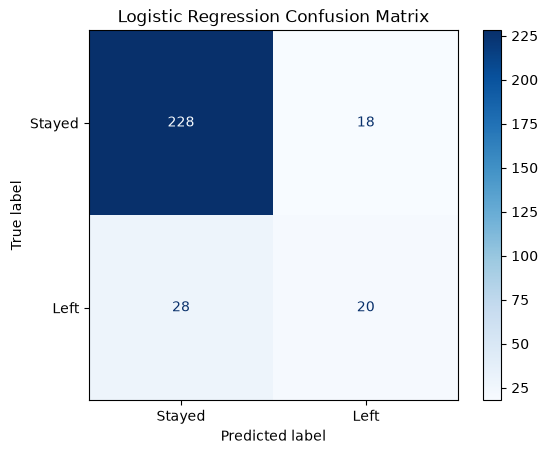

In [125]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

print(cm)

# Visualize confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Stayed', 'Left']
).plot(cmap='Blues')

plt.title('Logistic Regression Confusion Matrix')
plt.show()


### Confusion Matrix Analysis

I used a confusion matrix to evaluate how well my final Balanced Logistic Regression model predicted employee attrition on the test dataset of 294 employees.

The model correctly predicted 177 employees who stayed and 37 employees who left. However, it incorrectly predicted that 70 employees would leave when they actually stayed, while 10 employees who left were predicted to stay.

The model achieved a recall of **78.72%**, meaning it correctly identified most employees who left. However, its precision was **34.58%**, showing that it also made a considerable number of false-positive predictions.

Overall, the model performed reasonably well in identifying employees who left, but its low precision suggests that further improvements are needed to reduce incorrect predictions.

#### Model Improvement: Handling Class Imbalance

In [126]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

balanced_logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

balanced_logistic_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Age','BusinessTravel','DailyRate',...,'YearsInCurrentRole', 'YearsSinceLastPromotion','YearsWithCurrManager']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spec

In [127]:

balanced_pred = balanced_logistic_model.predict(X_val)

balanced_prob = balanced_logistic_model.predict_proba(
    X_val
)[:, 1]


              precision    recall  f1-score   support

      Stayed       0.94      0.73      0.82       246
        Left       0.36      0.77      0.49        48

    accuracy                           0.73       294
   macro avg       0.65      0.75      0.65       294
weighted avg       0.85      0.73      0.77       294

ROC-AUC: 0.8048780487804877


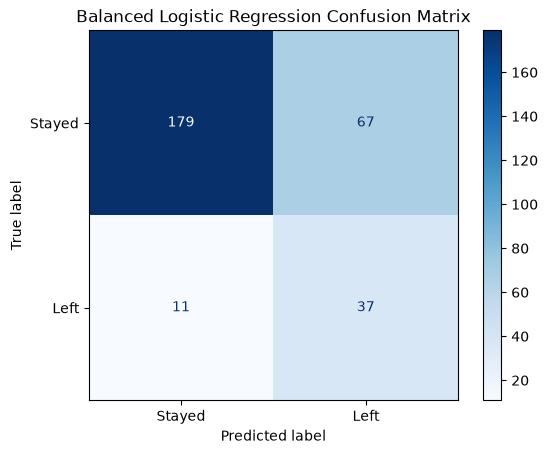

In [128]:

from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

print(classification_report(
    y_val,
    balanced_pred,
    target_names=['Stayed', 'Left'],
    zero_division=0
))

print(
    "ROC-AUC:",
    roc_auc_score(y_val, balanced_prob)
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    balanced_pred,
    display_labels=['Stayed', 'Left'],
    cmap='Blues'
)

plt.title('Balanced Logistic Regression Confusion Matrix')
plt.show()


### Balanced Logistic Regression

Since employees who left the company represent the minority class, I trained another Logistic Regression model using `class_weight='balanced'`. This gives more importance to the minority class during training and helps the model pay more attention to employees who left.

After applying this, recall improved from **41.67% to 77.08%**, meaning the model was able to identify more employees who actually left. However, precision dropped from **52.63% to 35.58%**, showing that the model also made more false-positive predictions.

Although accuracy decreased, the F1-score improved slightly from **46.51% to 48.68%**. This showed that balancing the classes helped improve the model's ability to identify employees who left, which was one of my main objectives.

#### Compare both models

In [129]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

comparison = pd.DataFrame({
    'Model': [
        'Standard Logistic Regression',
        'Balanced Logistic Regression'
    ],
    'Accuracy': [
        accuracy_score(y_val, y_val_pred),
        accuracy_score(y_val, balanced_pred)
    ],
    'Precision': [
        precision_score(y_val, y_val_pred),
        precision_score(y_val, balanced_pred)
    ],
    'Recall': [
        recall_score(y_val, y_val_pred),
        recall_score(y_val, balanced_pred)
    ],
    'F1-score': [
        f1_score(y_val, y_val_pred),
        f1_score(y_val, balanced_pred)
    ],
    'ROC-AUC': [
        roc_auc_score(y_val, y_val_prob),
        roc_auc_score(y_val, balanced_prob)
    ]
})

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Standard Logistic Regression,0.8435,0.5263,0.4167,0.4651,0.8076
1,Balanced Logistic Regression,0.7347,0.3558,0.7708,0.4868,0.8049


### Comparing Standard and Balanced Logistic Regression

I compared both Logistic Regression models using accuracy, precision, recall, F1-score and ROC-AUC to understand how balancing the classes affected their performance.

The standard model achieved a higher accuracy of **84.35%** and precision of **52.63%**, while the balanced model performed better in recall, improving from **41.67% to 77.08%**. The balanced model also achieved a slightly higher F1-score of **48.68%**, compared to **46.51%** for the standard model.

Although the balanced model produced more false positives, it was able to identify more employees who actually left the company. Based on these results, I considered it more suitable for my project's objective of identifying potential employee attrition.

#### Hyperparameter tuning

In [130]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define parameters to test
param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced']
}

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Hyperparameter tuning
grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1:", grid_search.best_score_)


Best Parameters: {'model__C': 10, 'model__class_weight': None}
Best Cross-Validation F1: 0.5190706802888331


### Logistic Regression Hyperparameter Tuning

I used `GridSearchCV` with five-fold stratified cross-validation to find the best combination of regularization strength (`C`) and class weighting for my Logistic Regression model. I selected F1-score as the evaluation metric because it considers both precision and recall, which is important for my imbalanced dataset.

After testing different parameter combinations, GridSearchCV selected **C = 10** and **class_weight = None**, with a cross-validation F1-score of **51.91%**.

However, when I evaluated the tuned model on the validation dataset, its F1-score was **43.68%**, which was lower than the **48.68%** achieved by Balanced Logistic Regression. This showed me that hyperparameter tuning does not always improve performance on unseen data, even when a parameter combination performs well during cross-validation.

###### Retrieve the best model

In [131]:

# Retrieve the best model from GridSearchCV
best_logistic_model = grid_search.best_estimator_

# Display the best model
best_logistic_model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Age','BusinessTravel','DailyRate',...,'YearsInCurrentRole', 'YearsSinceLastPromotion','YearsWithCurrManager']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spec

#### Evaluate the tuned model and update the comparison table

In [132]:

# Final comparison of all three Logistic Regression models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Retrieve the tuned model
best_logistic_model = grid_search.best_estimator_

# Predict using the tuned model
best_pred = best_logistic_model.predict(X_val)
best_prob = best_logistic_model.predict_proba(X_val)[:, 1]

# Models and their existing validation predictions
models = {
    'Standard Logistic Regression': (
        y_val_pred, y_val_prob
    ),
    'Balanced Logistic Regression': (
        balanced_pred, balanced_prob
    ),
    'Tuned Logistic Regression': (
        best_pred, best_prob
    )
}

# Compare performance
results = []

for name, (pred, prob) in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, pred),
        'Precision': precision_score(
            y_val, pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, pred, zero_division=0
        ),
        'F1-score': f1_score(
            y_val, pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_val, prob)
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Standard Logistic Regression,0.8435,0.5263,0.4167,0.4651,0.8076
1,Balanced Logistic Regression,0.7347,0.3558,0.7708,0.4868,0.8049
2,Tuned Logistic Regression,0.8333,0.4872,0.3958,0.4368,0.8090


### Evaluating the Tuned Logistic Regression Model

After hyperparameter tuning, I evaluated the best Logistic Regression model selected by `GridSearchCV` on the validation dataset and compared its performance with the standard and balanced models.

The tuned model achieved an accuracy of **83.33%**, precision of **48.72%**, recall of **39.58%**, F1-score of **43.68%**, and ROC-AUC of **80.90%**.

Although the tuned model had slightly better ROC-AUC, its F1-score was lower than the **48.68%** achieved by Balanced Logistic Regression. The balanced model also had a much higher recall of **77.08%**, meaning it identified more employees who actually left.

Based on these results, I kept Balanced Logistic Regression as my preferred candidate because identifying actual employee departures

#### Random Forest Classification

###### Import Random Forest

In [133]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline


Next, I tried Random Forest to compare a tree-based method with Logistic Regression. Random Forest combines predictions from many decision trees and can capture nonlinear relationships between employee features and attrition.

#### Create the Random Forest pipeline

In [134]:

# Create Random Forest pipeline
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

#### Train Random Forest

In [135]:

# Train Random Forest
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [136]:

# Predict employee attrition
rf_pred = rf_model.predict(X_val)

# Predict attrition probabilities
rf_prob = rf_model.predict_proba(X_val)[:, 1]

# Display first 10 predictions
rf_results = pd.DataFrame({
    'Actual': y_val.to_numpy(),
    'Predicted': rf_pred,
    'Probability': rf_prob
})

display(rf_results.head(10))


,Actual,Predicted,Probability
0,0,0,0.14
1,0,0,0.02
2,0,0,0.04
3,1,1,0.68
4,0,0,0.23
5,1,0,0.16
6,0,0,0.00
7,1,0,0.10
8,0,0,0.11
9,0,0,0.21


#### Evaluate Random Forest

In [137]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Random Forest Results")
print("---------------------")

print("Accuracy:", round(
    accuracy_score(y_val, rf_pred), 4
))

print("Precision:", round(
    precision_score(y_val, rf_pred, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_val, rf_pred, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_val, rf_pred, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_val, rf_prob), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_pred,
    target_names=['Stayed', 'Left'],
    zero_division=0
))


Random Forest Results
---------------------
Accuracy: 0.8503
Precision: 0.6429
Recall: 0.1875
F1-score: 0.2903
ROC-AUC: 0.7633

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.86      0.98      0.92       246
        Left       0.64      0.19      0.29        48

    accuracy                           0.85       294
   macro avg       0.75      0.58      0.60       294
weighted avg       0.83      0.85      0.81       294



### Evaluating the Baseline Random Forest Model

I evaluated the baseline Random Forest model using accuracy, precision, recall, F1-score, and ROC-AUC to compare its performance with Logistic Regression.

The model achieved an accuracy of **85.03%**, precision of **64.29%**, recall of **18.75%**, F1-score of **29.03%**, and ROC-AUC of **76.33%**.

Although Random Forest performed well in accuracy and precision, its low recall showed that it missed most employees who actually left the company. Compared to Balanced Logistic Regression, which achieved a recall of **77.08%** and F1-score of **48.68%**, Random Forest was less effective at identifying employees who left.

This showed me that accuracy alone is not enough to judge model performance, especially when the dataset is imbalanced.

#### Compare Random Forest with Logistic Regression

In [138]:

# Add Random Forest to existing comparison table
rf_comparison = pd.DataFrame([{
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_val, rf_pred),
    'Precision': precision_score(
        y_val, rf_pred, zero_division=0
    ),
    'Recall': recall_score(
        y_val, rf_pred, zero_division=0
    ),
    'F1-score': f1_score(
        y_val, rf_pred, zero_division=0
    ),
    'ROC-AUC': roc_auc_score(y_val, rf_prob)
}])

# Combine existing results with Random Forest
comparison_with_rf = pd.concat(
    [comparison_df, rf_comparison],
    ignore_index=True
)

display(comparison_with_rf.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Standard Logistic Regression,0.8435,0.5263,0.4167,0.4651,0.8076
1,Balanced Logistic Regression,0.7347,0.3558,0.7708,0.4868,0.8049
2,Tuned Logistic Regression,0.8333,0.4872,0.3958,0.4368,0.8090
3,Random Forest,0.8503,0.6429,0.1875,0.2903,0.7633


### Model Performance Comparison

I compared the four models using accuracy, precision, recall, F1-score, and ROC-AUC to understand their strengths and weaknesses.

Random Forest achieved the highest accuracy (**85.03%**) and precision (**64.29%**), but it had the lowest recall (**18.75%**), meaning it missed most employees who actually left the company.

Balanced Logistic Regression achieved the highest recall (**77.08%**) and F1-score (**48.68%**), although its accuracy was lower at **73.47%**. The tuned Logistic Regression achieved the highest ROC-AUC (**80.90%**), but this did not translate into a better F1-score.

Based on these results, I preferred Balanced Logistic Regression because it identified more employees who actually left while achieving the best balance between precision and recall, as measured by F1-score.

#### Random Forest Hyperparameter Tuning

In [139]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Parameters to test
rf_param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 10, None],
    'model__min_samples_leaf': [1, 5],
    'model__class_weight': [None, 'balanced']
}


#### GridSearchCV

In [140]:

# Stratified cross-validation
rf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Random Forest hyperparameter tuning
rf_grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_param_grid,
    scoring='f1',
    cv=rf_cv,
    n_jobs=-1,
    verbose=1
)

# Train and tune
rf_grid_search.fit(X_train, y_train)

# Display results
print("Best Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation F1:")
print(rf_grid_search.best_score_)


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}

Best Cross-Validation F1:
0.5106591231934983


### Random Forest Hyperparameter Tuning Results

After testing 24 parameter combinations using five-fold cross-validation, `GridSearchCV` selected the following best parameters:

- `n_estimators = 200`
- `max_depth = 5`
- `min_samples_leaf = 5`
- `class_weight = 'balanced'`

The best cross-validation F1-score was **51.07%**, showing that this combination performed best among the settings I tested.

The selected parameters suggest that limiting tree depth, requiring more samples in each leaf, and balancing the classes helped improve the model's performance during cross-validation.

However, I still needed to evaluate the tuned model on the validation dataset to confirm whether these improvements would carry over to unseen data.

#### Evaluate the tuned Random Forest

In [141]:

# Retrieve the best Random Forest model
best_rf_model = rf_grid_search.best_estimator_

# Make predictions
best_rf_pred = best_rf_model.predict(X_val)
best_rf_prob = best_rf_model.predict_proba(X_val)[:, 1]

# Evaluate
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

print("Tuned Random Forest Classification Report:")
print(classification_report(
    y_val,
    best_rf_pred,
    target_names=['Stayed', 'Left'],
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(y_val, best_rf_prob), 4
))


Tuned Random Forest Classification Report:
              precision    recall  f1-score   support

      Stayed       0.91      0.79      0.84       246
        Left       0.35      0.58      0.44        48

    accuracy                           0.76       294
   macro avg       0.63      0.69      0.64       294
weighted avg       0.82      0.76      0.78       294

ROC-AUC: 0.7888


### Evaluating the Tuned Random Forest Model

After hyperparameter tuning, I evaluated the best Random Forest model on the validation dataset to see whether its performance improved.

The tuned model achieved an accuracy of **75.51%**, precision of **35.00%**, recall of **58.33%**, F1-score of **43.75%**, and ROC-AUC of **78.88%**.

Compared to the baseline Random Forest, recall improved from **18.75% to 58.33%**, while the F1-score increased from **29.03% to 43.75%**. However, precision decreased, meaning the model incorrectly identified more employees as likely to leave.

Although tuning improved Random Forest's ability to identify employees who left, Balanced Logistic Regression still performed better, with a recall of **77.08%** and F1-score of **48.68%**.

#### Add the tuned Random Forest to our comparison

In [142]:

# Tuned Random Forest results
tuned_rf_result = pd.DataFrame([{
    'Model': 'Tuned Random Forest',
    'Accuracy': accuracy_score(y_val, best_rf_pred),
    'Precision': precision_score(
        y_val, best_rf_pred, zero_division=0
    ),
    'Recall': recall_score(
        y_val, best_rf_pred, zero_division=0
    ),
    'F1-score': f1_score(
        y_val, best_rf_pred, zero_division=0
    ),
    'ROC-AUC': roc_auc_score(y_val, best_rf_prob)
}])

# Extend the existing comparison table
comparison_with_tuned_rf = pd.concat(
    [comparison_with_rf, tuned_rf_result],
    ignore_index=True
)

display(comparison_with_tuned_rf.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Standard Logistic Regression,0.8435,0.5263,0.4167,0.4651,0.8076
1,Balanced Logistic Regression,0.7347,0.3558,0.7708,0.4868,0.8049
2,Tuned Logistic Regression,0.8333,0.4872,0.3958,0.4368,0.8090
3,Random Forest,0.8503,0.6429,0.1875,0.2903,0.7633
4,Tuned Random Forest,0.7551,0.3500,0.5833,0.4375,0.7888


### Model Comparison After Random Forest Tuning

Tuning improved Random Forest's F1-score from **29.03% to 43.75%** and recall from **18.75% to 58.33%**, although accuracy and precision decreased.

Balanced Logistic Regression still performed better in identifying employees who left, achieving the highest recall (**77.08%**) and F1-score (**48.68%**) among the five models.

#### XGBoost Classification

#### Install and import XGBoost

In [143]:

%pip install xgboost



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


#### Verify XGBoost installation

In [144]:

import xgboost as xgb
from xgboost import XGBClassifier

print("XGBoost Version:", xgb.__version__)


XGBoost Version: 3.4.1


### Installing and Verifying XGBoost

Before training my XGBoost model, I checked that the library was installed and could be imported successfully. XGBoost version **3.4.1** was available in my environment, so I could proceed with model training.

#### Create the baseline XGBoost model

In [145]:

# Create XGBoost pipeline

xgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

In [146]:

# Train XGBoost
xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")


XGBoost model trained successfully!




I trained an XGBoost model to see whether gradient boosting could improve employee attrition prediction compared to Logistic Regression and Random Forest.

I used the same preprocessing pipeline and training dataset to ensure a fair comparison. The pipeline handles missing values, scales numerical features, and encodes categorical features before training the XGBoost classifier.

After successfully training the model, I proceeded to evaluate its performance on the validation dataset using the same evaluation metrics as the previous models.

#### Generate predictions

In [147]:

# Predict employee attrition
xgb_pred = xgb_model.predict(X_val)

# Predict probabilities of attrition
xgb_prob = xgb_model.predict_proba(X_val)[:, 1]

# Display first 10 predictions
xgb_results = pd.DataFrame({
    'Actual': y_val.to_numpy(),
    'Predicted': xgb_pred,
    'Probability': xgb_prob
})

display(xgb_results.head(10))


,Actual,Predicted,Probability
0,0,0,0.165814
1,0,0,0.004018
2,0,0,0.021958
3,1,1,0.626620
4,0,0,0.272526
5,1,0,0.134615
6,0,0,0.035306
7,1,0,0.086409
8,0,0,0.036509
9,0,0,0.108420


### XGBoost Predictions

I used the trained XGBoost model to predict employee attrition on the validation dataset and calculated the probability of each employee leaving.

The first 10 predictions show that the model correctly identified some employees who stayed or left, but also missed two employees who actually left.

This helped me understand the model's predictions before evaluating its overall performance.

#### Evaluate XGBoost

In [148]:

# Evaluate baseline XGBoost

print("XGBoost Model Performance")
print("-------------------------")

print("Accuracy:", round(
    accuracy_score(y_val, xgb_pred), 4
))

print("Precision:", round(
    precision_score(y_val, xgb_pred, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_val, xgb_pred, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_val, xgb_pred, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_val, xgb_prob), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    xgb_pred,
    target_names=['Stayed', 'Left'],
    zero_division=0
))


XGBoost Model Performance
-------------------------
Accuracy: 0.8605
Precision: 0.64
Recall: 0.3333
F1-score: 0.4384
ROC-AUC: 0.8037

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.88      0.96      0.92       246
        Left       0.64      0.33      0.44        48

    accuracy                           0.86       294
   macro avg       0.76      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



### XGBoost Model Evaluation

The XGBoost model achieved an accuracy of **86.05%**, precision of **64.00%**, recall of **33.33%**, F1-score of **43.84%**, and ROC-AUC of **80.37%**.

Although XGBoost achieved higher accuracy than the previous models, its low recall showed that it missed many employees who actually left.

Balanced Logistic Regression still performed better at identifying employees who left, with a recall of **77.08%** and F1-score of **48.68%**.

#### Add XGBoost to the existing comparison table

In [149]:

# Create XGBoost results
xgb_comparison = pd.DataFrame([{
    'Model': 'XGBoost',
    'Accuracy': accuracy_score(y_val, xgb_pred),
    'Precision': precision_score(
        y_val, xgb_pred, zero_division=0
    ),
    'Recall': recall_score(
        y_val, xgb_pred, zero_division=0
    ),
    'F1-score': f1_score(
        y_val, xgb_pred, zero_division=0
    ),
    'ROC-AUC': roc_auc_score(y_val, xgb_prob)
}])

# Add XGBoost to our existing comparison
comparison_with_xgb = pd.concat(
    [comparison_with_tuned_rf, xgb_comparison],
    ignore_index=True
)

display(comparison_with_xgb.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Standard Logistic Regression,0.8435,0.5263,0.4167,0.4651,0.8076
1,Balanced Logistic Regression,0.7347,0.3558,0.7708,0.4868,0.8049
2,Tuned Logistic Regression,0.8333,0.4872,0.3958,0.4368,0.8090
3,Random Forest,0.8503,0.6429,0.1875,0.2903,0.7633
4,Tuned Random Forest,0.7551,0.3500,0.5833,0.4375,0.7888
5,XGBoost,0.8605,0.6400,0.3333,0.4384,0.8037




I compared all six models to see whether XGBoost improved the prediction results.

XGBoost achieved the highest accuracy (**86.05%**), but Balanced Logistic Regression still had the highest recall (**77.08%**) and F1-score (**48.68%**).

Based on these results, Balanced Logistic Regression remained my preferred model because it identified more employees who actually left the company.

#### XGBoost Hyperparameter Tuning

In [150]:

# Calculate the class imbalance ratio
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Scale Positive Weight:", round(scale_pos_weight, 4))


Scale Positive Weight: 5.2113


### XGBoost Hyperparameter Tuning – Class Imbalance

Before tuning XGBoost, I calculated the class imbalance ratio using the number of employees who stayed compared to those who left.

The result was **5.2113**, meaning there were approximately five employees who stayed for every employee who left in the training dataset.

I used this value to guide the tuning of `scale_pos_weight`, which can help XGBoost pay more attention to the minority class.

#### Define the XGBoost parameter grid

In [151]:

# Define parameters for XGBoost tuning

xgb_param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [3, 5],
    'model__learning_rate': [0.05, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__scale_pos_weight': [
        1,
        scale_pos_weight
    ]
}


#### Run GridSearchCV

In [152]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Stratified cross-validation
xgb_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Configure GridSearchCV
xgb_grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_param_grid,
    scoring='f1',
    cv=xgb_cv,
    n_jobs=-1,
    verbose=1
)

# Train and tune XGBoost
xgb_grid_search.fit(X_train, y_train)

# Display best results
print("Best XGBoost Parameters:")
print(xgb_grid_search.best_params_)

print("\nBest Cross-Validation F1:")
print(xgb_grid_search.best_score_)


Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best XGBoost Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__scale_pos_weight': np.float64(5.211267605633803), 'model__subsample': 0.8}

Best Cross-Validation F1:
0.48536997692158623




I used `GridSearchCV` with five-fold cross-validation to test 32 parameter combinations and improve my XGBoost model.

The best parameters were `learning_rate=0.1`, `max_depth=3`, `n_estimators=100`, `scale_pos_weight=5.2113`, and `subsample=0.8`.

The best cross-validation F1-score was **48.54%**. I then needed to evaluate the tuned model on the validation dataset to see whether these settings improved its performance compared to the baseline XGBoost model.

#### Evaluate the tuned XGBoost model

In [153]:

# Retrieve best tuned XGBoost model
best_xgb_model = xgb_grid_search.best_estimator_

# Generate validation predictions
best_xgb_pred = best_xgb_model.predict(X_val)

best_xgb_prob = best_xgb_model.predict_proba(
    X_val
)[:, 1]

# Display classification report
print("Tuned XGBoost Classification Report:")
print(classification_report(
    y_val,
    best_xgb_pred,
    target_names=['Stayed', 'Left'],
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(y_val, best_xgb_prob), 4
))


Tuned XGBoost Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.84      0.87       246
        Left       0.39      0.52      0.45        48

    accuracy                           0.79       294
   macro avg       0.65      0.68      0.66       294
weighted avg       0.82      0.79      0.80       294

ROC-AUC: 0.7997


#### Add tuned XGBoost to the comparison table

In [154]:

# Tuned XGBoost performance
tuned_xgb_result = pd.DataFrame([{
    'Model': 'Tuned XGBoost',
    'Accuracy': accuracy_score(y_val, best_xgb_pred),
    'Precision': precision_score(
        y_val, best_xgb_pred, zero_division=0
    ),
    'Recall': recall_score(
        y_val, best_xgb_pred, zero_division=0
    ),
    'F1-score': f1_score(
        y_val, best_xgb_pred, zero_division=0
    ),
    'ROC-AUC': roc_auc_score(y_val, best_xgb_prob)
}])

# Extend our existing comparison table
comparison_all = pd.concat(
    [comparison_with_xgb, tuned_xgb_result],
    ignore_index=True
)

display(comparison_all.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Standard Logistic Regression,0.8435,0.5263,0.4167,0.4651,0.8076
1,Balanced Logistic Regression,0.7347,0.3558,0.7708,0.4868,0.8049
2,Tuned Logistic Regression,0.8333,0.4872,0.3958,0.4368,0.8090
3,Random Forest,0.8503,0.6429,0.1875,0.2903,0.7633
4,Tuned Random Forest,0.7551,0.3500,0.5833,0.4375,0.7888
5,XGBoost,0.8605,0.6400,0.3333,0.4384,0.8037
6,Tuned XGBoost,0.7891,0.3906,0.5208,0.4464,0.7997




After evaluating all seven models, I found that XGBoost achieved the highest accuracy (**86.05%**), while Balanced Logistic Regression had the highest recall (**77.08%**) and F1-score (**48.68%**).

Although tuning improved XGBoost's recall from **33.33% to 52.08%**, its F1-score remained lower than Balanced Logistic Regression.

Based on these results, I selected **Balanced Logistic Regression** as my final model because it performed best at identifying employees who left while maintaining the highest F1-score.

#### Classification Threshold Optimization

Test different thresholds

In [155]:

# Classification threshold analysis
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Define thresholds to evaluate
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    # Convert probabilities into binary predictions
    predictions = (
        balanced_prob >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    threshold_results.append({
        'Threshold': round(threshold, 2),
        'Precision': precision_score(
            y_val, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_val, predictions, zero_division=0
        ),
        'F1-score': f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1-score
0,0.10,0.2120,0.9583,0.3472
1,0.15,0.2368,0.9375,0.3782
2,0.20,0.2635,0.9167,0.4093
3,0.25,0.2829,0.8958,0.4300
4,0.30,0.2867,0.8542,0.4293
5,0.35,0.3150,0.8333,0.4571
6,0.40,0.3223,0.8125,0.4615
7,0.45,0.3363,0.7917,0.4720
8,0.50,0.3558,0.7708,0.4868
9,0.55,0.3696,0.7083,0.4857


### Classification Threshold Evaluation

I tested different classification thresholds for Balanced Logistic Regression to see whether I could improve the balance between precision and recall.

The default threshold of **0.50** produced the highest F1-score of **48.68%**, with a recall of **77.08%** and precision of **35.58%**.

Lower thresholds improved recall but reduced precision, while higher thresholds generally increased precision at the cost of recall. Based on these results, I kept the **0.50 threshold** for my final model.

#### Visualize the threshold results

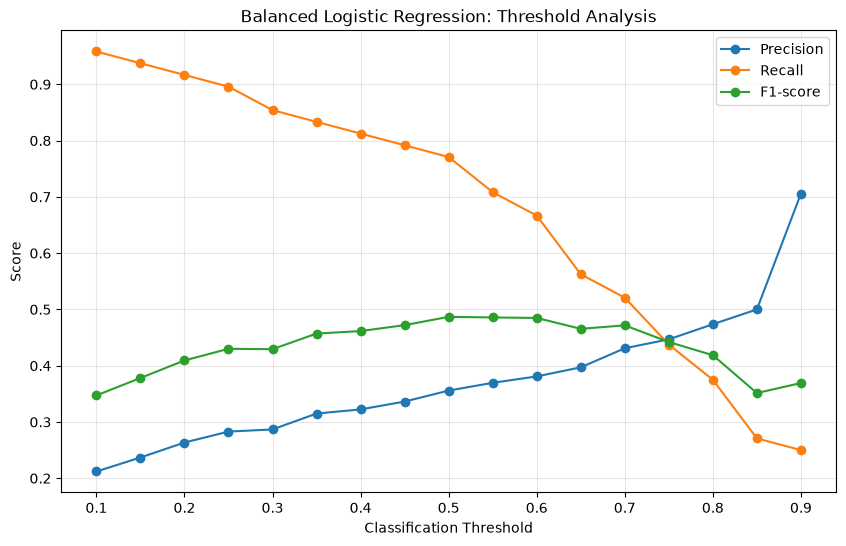

In [156]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1-score'],
    marker='o',
    label='F1-score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Balanced Logistic Regression: Threshold Analysis')

plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Classification Threshold Analysis

I plotted precision, recall, and F1-score across different classification thresholds to understand how changing the threshold affects model performance.

The graph shows that precision generally increases as the threshold rises, while recall decreases. The F1-score reached its highest value of **48.68% at a threshold of 0.50**.

Based on this analysis, I kept the default threshold of **0.50** because it provided the best balance between precision and recall among the thresholds tested.

#### Identify the best threshold

In [157]:

# Find the threshold with the highest F1-score
best_threshold_row = threshold_df.loc[
    threshold_df['F1-score'].idxmax()
]

best_threshold = float(best_threshold_row['Threshold'])

print("Best Threshold:", best_threshold)

print(
    "Best F1-score:",
    round(best_threshold_row['F1-score'], 4)
)

print(
    "Precision:",
    round(best_threshold_row['Precision'], 4)
)

print(
    "Recall:",
    round(best_threshold_row['Recall'], 4)
)


Best Threshold: 0.5
Best F1-score: 0.4868
Precision: 0.3558
Recall: 0.7708




The results confirmed that **0.50** was the best classification threshold, achieving an F1-score of **48.68%**, precision of **35.58%**, and recall of **77.08%**.

I therefore kept this threshold for my final Balanced Logistic Regression model, as it provided the highest F1-score among the thresholds tested.

#### Feature Importance Using Permutation Importance

In [158]:

from sklearn.inspection import permutation_importance




I used permutation importance to identify which features contributed most to my Balanced Logistic Regression model's predictions.

This method measures how much the model's performance changes when the values of each feature are randomly shuffled. A larger decrease in performance indicates that the model relies more heavily on that feature.

###### Calculate feature importance

In [159]:

# Calculate permutation importance
perm_importance = permutation_importance(
    balanced_logistic_model,
    X_val,
    y_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create feature importance DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': X_val.columns,
    'Importance': perm_importance.importances_mean,
    'Std': perm_importance.importances_std
})

# Sort features by importance
feature_importance_df = (
    feature_importance_df
    .sort_values('Importance', ascending=False)
    .reset_index(drop=True)
)

display(feature_importance_df)


,Feature,Importance,Std
0,OverTime,0.084384,0.016971
1,MonthlyIncome,0.074499,0.025672
2,YearsInCurrentRole,0.063488,0.021906
3,MaritalStatus,0.051366,0.024678
4,YearsWithCurrManager,0.049816,0.027295
5,JobRole,0.049126,0.029028
6,EnvironmentSatisfaction,0.039082,0.010933
7,DistanceFromHome,0.032448,0.014010
8,JobSatisfaction,0.032205,0.015683
9,TotalWorkingYears,0.027915,0.014323




The results showed that **OverTime, MonthlyIncome, YearsInCurrentRole, MaritalStatus, and YearsWithCurrManager** were the five most important features in my Balanced Logistic Regression model.

OverTime had the highest importance score (**0.0844**), followed by MonthlyIncome (**0.0745**). This means the model relied more on these features when predicting employee attrition.

These results helped me understand which features influenced the model's predictions most, although they do not necessarily mean these factors directly cause employees to leave.

#### Visualize the 15 most important features

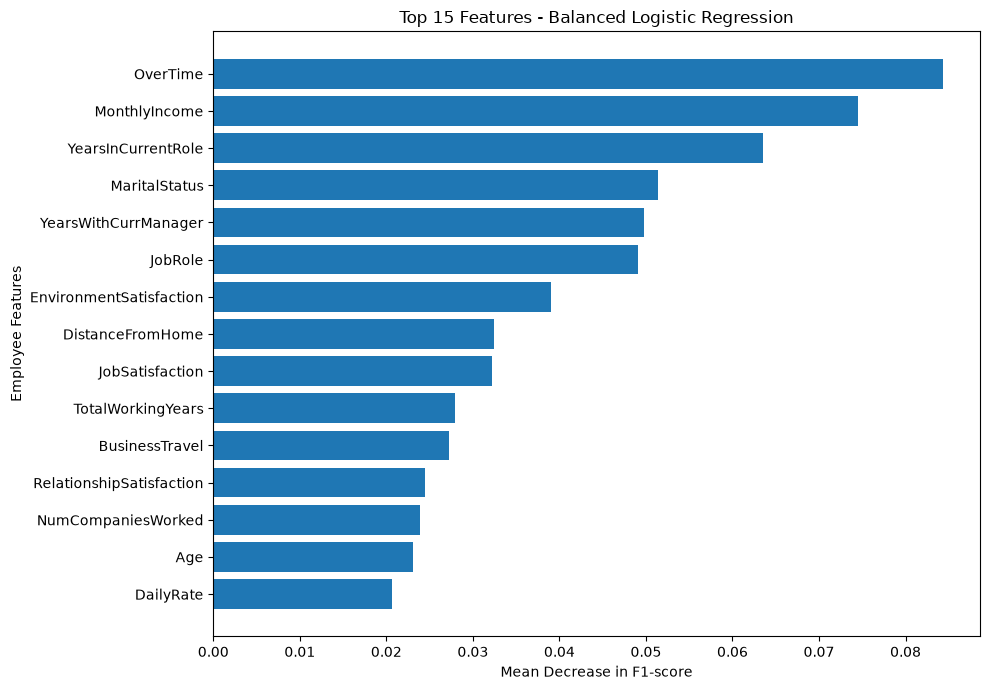

In [160]:

import matplotlib.pyplot as plt

# Select the 15 highest-ranked features
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Mean Decrease in F1-score')
plt.ylabel('Employee Features')
plt.title('Top 15 Features - Balanced Logistic Regression')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


I plotted the top 15 features to better understand which variables contributed most to my Balanced Logistic Regression model's predictions.

The chart shows that **OverTime, MonthlyIncome, and YearsInCurrentRole** had the highest permutation importance scores, followed by MaritalStatus and YearsWithCurrManager.

These features had the greatest impact on the model's F1-score when shuffled, suggesting that the model relied on them more heavily when predicting employee attrition.

#### Final Model Selection and Test Evaluation

Prepare the final training dataset

In [161]:

# Combine training and validation features
X_full_train = pd.concat(
    [X_train, X_val],
    ignore_index=True
)

# Combine training and validation targets
y_full_train = pd.concat(
    [
        pd.Series(y_train),
        pd.Series(y_val)
    ],
    ignore_index=True
)

print("Final Training Features:", X_full_train.shape)
print("Final Training Target:", y_full_train.shape)
print("Test Features:", X_test.shape)


Final Training Features: (1176, 30)
Final Training Target: (1176,)
Test Features: (294, 30)


After selecting Balanced Logistic Regression as my final model, I combined the training and validation datasets to give the model more data for its final training.

This produced **1,176 employee records with 30 features**, while the remaining **294 records** were kept separate for final testing on unseen data.

In [162]:

from sklearn.base import clone

# Create a fresh copy of our selected model
final_model = clone(balanced_logistic_model)

# Train on all 1,176 training employees
final_model.fit(X_full_train, y_full_train)

print("Final Balanced Logistic Regression trained successfully!")


Final Balanced Logistic Regression trained successfully!


In [163]:

# Generate predictions using the final model
y_test_pred = final_model.predict(X_test)

# Generate attrition probabilities
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Display the first 10 predictions
final_test_results = pd.DataFrame({
    'Actual': np.asarray(y_test),
    'Predicted': y_test_pred,
    'Probability': y_test_prob
})

display(final_test_results.head(10))


,Actual,Predicted,Probability
0,0,0,0.196049
1,0,1,0.675859
2,0,0,0.230241
3,0,1,0.741356
4,0,1,0.667086
5,0,0,0.036741
6,1,1,0.986296
7,0,0,0.342660
8,0,0,0.060171
9,0,0,0.113449


I used my final Balanced Logistic Regression model to predict employee attrition on the unseen test dataset.

The first 10 results show the actual outcomes, predicted outcomes, and probability of each employee leaving. The model correctly predicted 7 out of these 10 cases but incorrectly flagged 3 employees as likely to leave.

I then evaluated the model on the full test dataset to measure its overall performance.

#### Evaluate the model's performance

In [164]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("FINAL MODEL TEST RESULTS")
print("------------------------")

print("Accuracy:", round(
    accuracy_score(y_test, y_test_pred), 4
))

print("Precision:", round(
    precision_score(y_test, y_test_pred), 4
))

print("Recall:", round(
    recall_score(y_test, y_test_pred), 4
))

print("F1-score:", round(
    f1_score(y_test, y_test_pred), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_test_prob), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=['Stayed', 'Left']
))


FINAL MODEL TEST RESULTS
------------------------
Accuracy: 0.7279
Precision: 0.3458
Recall: 0.7872
F1-score: 0.4805
ROC-AUC: 0.8409

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.95      0.72      0.82       247
        Left       0.35      0.79      0.48        47

    accuracy                           0.73       294
   macro avg       0.65      0.75      0.65       294
weighted avg       0.85      0.73      0.76       294





I evaluated my final Balanced Logistic Regression model on the 294 unseen test records to check how well it performed on new data.

The model achieved an accuracy of **72.79%**, precision of **34.58%**, recall of **78.72%**, F1-score of **48.05%**, and ROC-AUC of **84.09%**.

The high recall showed that the model successfully identified most employees who left, although its low precision indicated a considerable number of false positives. Overall, the results were consistent with my objective of prioritizing the identification of employees who may leave.

#### Display the final confusion matrix

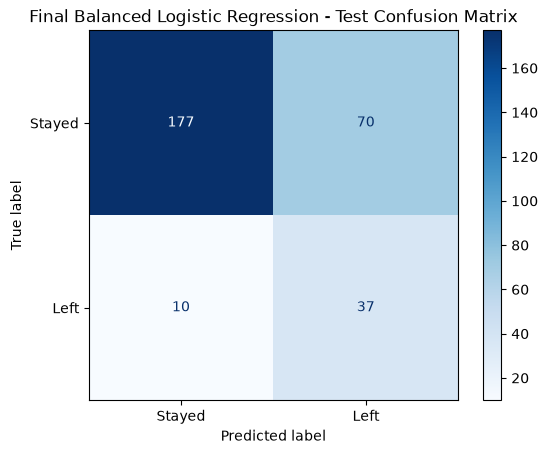

In [165]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=['Stayed', 'Left'],
    cmap='Blues',
    values_format='d'
)

plt.title(
    'Final Balanced Logistic Regression - Test Confusion Matrix'
)

plt.show()


The confusion matrix shows that my final Balanced Logistic Regression model correctly predicted **177 employees who stayed** and **37 employees who left**.

However, it incorrectly predicted that 70 employees would leave when they actually stayed, while 10 employees who left were predicted to stay.

This confirms that the model identified most employees who actually left, but it also produced a considerable number of false positives, which explains its high recall and relatively low precision.

#### Save the Final Model

In [166]:

import pickle

# Save the final trained pipeline
with open('employee_attrition_model.pkl', 'wb') as file:
    pickle.dump(final_model, file)

print("Model saved successfully!")


Model saved successfully!


#### Verify the saved model

In [167]:

# Load the saved model
with open('employee_attrition_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

# Verify that predictions are identical
original_predictions = final_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

print(
    "Predictions identical:",
    np.array_equal(
        original_predictions,
        loaded_predictions
    )
)


Predictions identical: True


### Saving and Verifying the Final Model

I saved my final Balanced Logistic Regression model as `employee_attrition_model.pkl` using Python's `pickle` library so I could reuse it without retraining.

I then loaded the saved model and compared its predictions with the original model. The result, **`Predictions identical: True`**, confirmed that the saved model was loaded successfully and produced the same predictions.

The model is now ready to be integrated into a Flask application for deployment.

#### Creating train.py

In [168]:

%%writefile train.py

import pickle
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Load the dataset
df = pd.read_csv("New_HR-Employee-Attrition.csv")

# 2. Remove unnecessary columns
columns_to_drop = [
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
]
df = df.drop(columns=columns_to_drop)

# 3. Prepare the target and features
y = df["Attrition"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["Attrition"])

# 4. Identify numerical and categorical features
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_columns = X.select_dtypes(include=["object", "category"]).columns.tolist()

# 5. Create preprocessing pipelines
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

# 6. Split the dataset
X_full_train, X_test, y_full_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=1,
    stratify=y
)

# 7. Create the final model
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=1
    ))
])

# 8. Train the model
final_model.fit(X_full_train, y_full_train)

# 9. Evaluate on the test dataset
predictions = final_model.predict(X_test)
probabilities = final_model.predict_proba(X_test)[:, 1]

print("FINAL MODEL TEST RESULTS")
print("------------------------")
print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("Precision:", round(precision_score(y_test, predictions), 4))
print("Recall:", round(recall_score(y_test, predictions), 4))
print("F1-score:", round(f1_score(y_test, predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))

# 10. Save the model separately until results are verified
with open("employee_attrition_model_from_script.pkl", "wb") as file:
    pickle.dump(final_model, file)

print("\nModel trained and saved successfully!")


Overwriting train.py


I created train.py to make my model training process reproducible outside Jupyter Notebook. The script loads the dataset, prepares the features, trains Balanced Logistic Regression, evaluates its performance, and saves the trained model.

In [169]:

!python train.py


/workspaces/machine-learning-zoomcamp-homework/train.py:31: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=["object", "category"]).columns.tolist()
FINAL MODEL TEST RESULTS
------------------------
Accuracy: 0.7279
Precision: 0.3458
Recall: 0.7872
F1-score: 0.4805
ROC-AUC: 0.8409

Model trained and saved successfully!


I successfully ran train.py again.

The model achieved 72.79% accuracy, 34.58% precision, 78.72% recall, 48.05% F1-score, and 84.09% ROC-AUC. These results match my original notebook, confirming that my training script reproduces the final model's performance.

The model was also saved successfully for deployment.

#### Flask deployment

In [170]:

%%writefile predict.py

import pickle
import pandas as pd
from flask import Flask, request, jsonify

with open("employee_attrition_model_from_script.pkl", "rb") as f:
    model = pickle.load(f)

app = Flask(__name__)

@app.route("/predict", methods=["POST"])
def predict():
    employee = request.get_json()
    employee_df = pd.DataFrame([employee])

    probability = float(model.predict_proba(employee_df)[0, 1])
    attrition = bool(probability >= 0.5)

    return jsonify({
        "attrition_probability": probability,
        "attrition": attrition
    })

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=9696)


Overwriting predict.py


### Creating the Flask Prediction API

I created a `predict.py` file using Flask to make my trained employee attrition model available for predictions.

The API loads my saved model, accepts employee information in JSON format, and returns the probability of attrition along with a True or False prediction.

The file was saved successfully and is ready for testing.

In [172]:

import requests

# Select one employee from the test dataset
employee = X_test.iloc[0].to_dict()

# Send the employee information to Flask
response = requests.post(
    "http://127.0.0.1:9696/predict",
    json=employee
)

print("Status code:", response.status_code)
print("Prediction:", response.json())


Status code: 200
Prediction: {'attrition': False, 'attrition_probability': 0.19604865171871816}


### Testing the Flask Prediction API

I successfully tested my Flask API using an employee record from the test dataset. The API returned a status code of 200, confirming that the request was successful.

The model predicted a 19.60% probability of attrition and returned `False`, meaning the employee is predicted to stay. This confirms that my saved model can make predictions through the Flask API.

#### Create requirements.txt

In [177]:

%%writefile requirements.txt
flask==3.1.3
pandas==3.0.6
numpy==2.5.3
scikit-learn==1.9.1
scipy==1.18.1


Overwriting requirements.txt


#### Create the Dockerfile

In [180]:

%%writefile Dockerfile
FROM python:3.14-slim

WORKDIR /app

COPY requirements.txt .

RUN pip install --no-cache-dir -r requirements.txt

COPY predict.py .
COPY employee_attrition_model_from_script.pkl .

EXPOSE 9696

CMD ["python", "predict.py"]


Overwriting Dockerfile


In [181]:
import sys
import sklearn
import pandas
import numpy
import scipy
import flask

print("Python:", sys.version.split()[0])
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("Flask:", flask.__version__)

Python: 3.14.2
Scikit-learn: 1.9.1
Pandas: 3.0.6
NumPy: 2.5.3
SciPy: 1.18.1
Flask: 3.1.3


/tmp/ipykernel_61625/380436517.py:13: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print("Flask:", flask.__version__)


In [183]:
!docker --version

Docker version 29.8.0-1, build 88096ef00576baf72a9cb45caa45c0544c40e0a7


I checked whether Docker was installed in my development environment. The command confirmed that Docker version 29.8.0 is available, allowing me to proceed with containerizing my Flask application.

In [184]:
!docker build -t employee-attrition-api .





[+] Building 0.0s (0/1)                                          docker:default
[+] Building 0.2s (0/1)                                          docker:default
 => [internal] load build definition from Dockerfile                       0.1s
[+] Building 0.2s (0/1)                                          docker:default
 => [internal] load build definition from Dockerfile                       0.1s
 => => transferring dockerfile:                                            0.0s
[+] Building 0.3s (0/1)                                          docker:default
 => [internal] load build definition from Dockerfile                       0.3s
 => => transferring dockerfile: 30B                                        0.1s
[+] Building 0.5s (1/3)                                          docker:default
 => [internal] load build definition from Dockerfile                       0.3s
 => => transferring dockerfile: 262B                                       0.1s
 => [internal] load metadata for doc

#### Running Docker container

In [185]:
!docker run -d -p 9697:9696 --name attrition-container employee-attrition-api

a45eae5ba47bc387f436d7ecf18e8057f24f253d698795fdfb0d96fd407f7f58


In [186]:
!docker ps

CONTAINER ID   IMAGE                    COMMAND               CREATED          STATUS          PORTS                                         NAMES
a45eae5ba47b   employee-attrition-api   "python predict.py"   30 seconds ago   Up 29 seconds   0.0.0.0:9697->9696/tcp, [::]:9697->9696/tcp   attrition-container


#### Testing the Docker API

In [187]:

import requests

employee = X_test.iloc[0].to_dict()

response = requests.post(
    "http://127.0.0.1:9697/predict",
    json=employee
)

print("Status code:", response.status_code)
print("Prediction:", response.json())


Status code: 200
Prediction: {'attrition': False, 'attrition_probability': 0.19604865171871816}




I successfully tested my employee attrition prediction API running inside Docker. The API returned a status code of 200, confirming that the request was successful.

The model predicted a 19.60% probability of attrition and returned `False`, indicating that the employee is predicted to stay.

These results match my earlier Flask API test, confirming that my application works correctly inside the Docker container.

#### Create Read me

In [188]:

%%writefile README.md
# Employee Attrition Prediction

## Project Overview
This Machine Learning Zoomcamp capstone project predicts
whether an employee is likely to leave a company.

## Dataset
IBM HR Analytics Employee Attrition & Performance dataset.
The dataset contains 1,470 employee records.

## Model
I compared Logistic Regression, Random Forest, and XGBoost.
I selected Balanced Logistic Regression because identifying
employees at risk of leaving was my priority.

## Final Model Performance
- Accuracy: 72.79%
- Precision: 34.58%
- Recall: 78.72%
- F1-score: 48.05%
- ROC-AUC: 84.09%

## Project Files
- train.py: Trains and saves the model
- predict.py: Flask prediction API
- requirements.txt: Python dependencies
- Dockerfile: Container configuration
- employee_attrition_model_from_script.pkl: Trained model

## Run Locally
pip install -r requirements.txt
python predict.py

## Run with Docker
docker build -t employee-attrition-api .
docker run -p 9697:9696 employee-attrition-api

## API
POST /predict

Send employee features as JSON.

The API returns:
- attrition: True or False
- attrition_probability: Probability of leaving

## Conclusion
The model can help identify employees who may be at risk
of leaving. Predictions are estimates and should not be
used as the sole basis for employment decisions.


Overwriting README.md


In [189]:
!git remote -v

origin	https://github.com/Ajibola4real/machine-learning-zoomcamp-homework (fetch)
origin	https://github.com/Ajibola4real/machine-learning-zoomcamp-homework (push)


In [191]:
!git status --short

 M README.md
?? .vscode/
?? Advertising.csv
?? Car_Price_Prediction.ipynb
?? Classification_Class3.ipynb
?? Dockerfile
?? HR_Employee_Attrition.ipynb
?? "Homework 2 - Linear Regression"
?? New_HR-Employee-Attrition.csv
?? NumPy.ipynb
?? Pipfile
?? Pipfile.lock
?? USA_Housing.csv
?? Untitled.ipynb
?? Untitled1.ipynb
?? Untitled2.ipynb
?? Untitled3.ipynb
?? Untitled4.ipynb
?? Untitled5.ipynb
?? Untitled6.ipynb
?? WA_Fn-UseC_-HR-Employee-Attrition.csv
?? car_fuel_efficiency_2026.csv
?? car_fuel_efficiency_2026.csv.1
?? car_fuel_efficiency_2026.csv.2
?? car_fuel_efficiency_2026.csv.3
?? car_fuel_efficiency_2026.csv.4
?? course_lead_scoring.csv
?? course_lead_scoring_2026.csv
?? course_lead_scoring_2026.csv.1
?? course_lead_scoring_2026.csv.2
?? course_lead_scoring_2026.csv.3
?? course_lead_scoring_2026.csv.4
?? course_lead_scoring_2026.csv.5
?? course_lead_scoring_2026.ipynb
?? data-week-3.csv
?? data.csv
?? data.csv.1
?? data.csv.2
?? data.csv.3
?? data.csv.4
?? data.csv.5
?? employee_att

In [192]:
!git add README.md Dockerfile HR_Employee_Attrition.ipynb New_HR-Employee-Attrition.csv train.py predict.py requirements.txt employee_attrition_model_from_script.pkl